# 06 · Robustness checks and the numbers the paper cites

1. Re-estimates the main H2–H4 coefficient under alternative exposure measures, weights, samples and a placebo date.
2. Collects every number cited in the paper into `output/numbers_for_paper.json` and a one-page verdict table. Any figure quoted in the manuscript should be traceable to this file.

In [1]:
from rwm_common import *
set_style()
rows = []
def run(label, p, y="lemp", w=None, fe="C(year)", term_col="ez", post_col="post"):
    t, _ = pooled(p, y, {"x": p[term_col] * p[post_col]}, fe=fe, weights=w, label=label)
    rows.append(t.assign(outcome=y))

# Baseline
p0, yrs = prepare_occ_panel(MAIN_WINDOW, "beta_gpt")
run("Baseline (GPT-4 beta)", p0)
# Exposure measures
for col in ["beta_human", "alpha_gpt", "gamma_gpt", "alpha_human"]:
    p, _ = prepare_occ_panel(MAIN_WINDOW, col); run(f"Exposure = {col}", p)
# Binary: top exposure tercile
p = p0.copy(); p["top3"] = (p["ez"] >= p.drop_duplicates("soc")["ez"].quantile(2/3)).astype(int)
run("Top exposure tercile (binary)", p, term_col="top3")
# Weights and fixed effects
run("Employment-weighted", p0, w="w")
run("Major group × year FE", p0, fe="major_year")
# Extended window 2019-2025, all years and without pandemic years
pe, _ = prepare_occ_panel((2019, 2025), "beta_gpt"); run("Extended 2019–2025", pe)
pe2, _ = prepare_occ_panel((2019, 2025), "beta_gpt", drop_years=(2020, 2021)); run("Extended, drop 2020–21", pe2)
# Placebo: pretend treatment started in 2021, using only pre-ChatGPT years 2019-2022
pp, _ = prepare_occ_panel((2019, 2022), "beta_gpt"); pp["post_fake"] = (pp["year"] >= 2021).astype(int)
run("Placebo: post = 2021–22 (2019–22 only)", pp, post_col="post_fake")
# Same checks for the dispersion outcome
pn = p0[~p0["p90_topcoded_any"].astype(bool)]
run("P90/P10 baseline", pn, y="l9010")
ph, _ = prepare_occ_panel(MAIN_WINDOW, "beta_human"); ph = ph[~ph["p90_topcoded_any"].astype(bool)]
run("P90/P10, human exposure", ph, y="l9010")

rob = pd.concat(rows).reset_index(drop=True)[["model", "outcome", "coef", "se", "p", "ci_low", "ci_high", "n_obs"]]
rob["sig"] = rob["p"].map(stars)
save_table(rob.set_index(["outcome", "model"]), "table6_robustness",
           "Robustness: coefficient on exposure × post-2022 (occupation and year FE; SEs clustered by occupation)")
rob.round(4)

Saved table table6_robustness


,model,outcome,coef,se,p,ci_low,ci_high,n_obs,sig
0,Baseline (GPT-4 beta),lemp,0.0046,0.0055,0.3979,-0.0061,0.0154,3850,
1,Exposure = beta_human,lemp,0.0132,0.0051,0.0095,0.0032,0.0232,3850,***
2,Exposure = alpha_gpt,lemp,-0.0113,0.0050,0.0239,-0.0210,-0.0015,3850,**
3,Exposure = gamma_gpt,lemp,0.0113,0.0052,0.0307,0.0011,0.0215,3850,**
4,Exposure = alpha_human,lemp,0.0086,0.0053,0.1045,-0.0018,0.0190,3850,
5,Top exposure tercile (binary),lemp,0.0002,0.0105,0.9867,-0.0203,0.0207,3850,
6,Employment-weighted,lemp,-0.0101,0.0071,0.1548,-0.0241,0.0038,3850,
7,Major group × year FE,lemp,-0.0191,0.0094,0.0417,-0.0375,-0.0007,3850,**
8,Extended 2019–2025,lemp,0.0141,0.0070,0.0453,0.0003,0.0278,4942,**
9,"Extended, drop 2020–21",lemp,0.0166,0.0068,0.0138,0.0034,0.0299,3535,**


## Figure 8. Robustness of the employment coefficient

Saved figure fig8_robustness


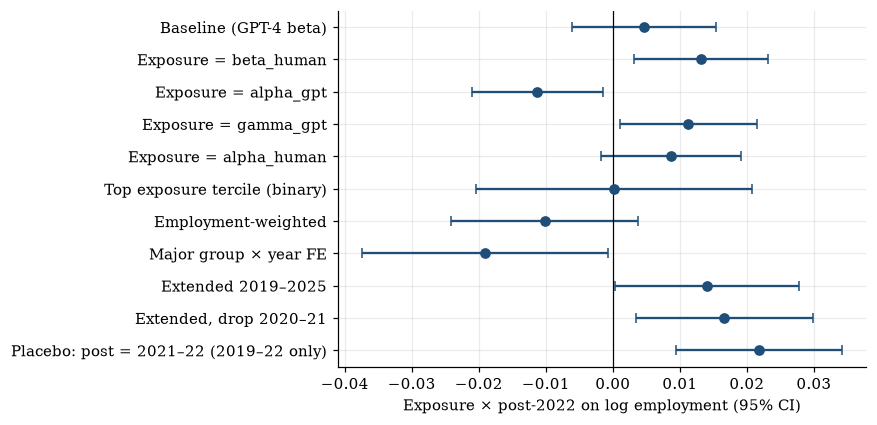

In [2]:
import matplotlib.pyplot as plt
r = rob[rob["outcome"] == "lemp"].iloc[::-1]
fig, ax = plt.subplots(figsize=(6.2, 4.2))
ax.errorbar(r["coef"], range(len(r)), xerr=[r["coef"] - r["ci_low"], r["ci_high"] - r["coef"]],
            fmt="o", color=PALETTE["main"], capsize=3)
ax.axvline(0, color="black", lw=0.8)
ax.set_yticks(range(len(r)), r["model"]); ax.set_xlabel("Exposure × post-2022 on log employment (95% CI)")
save_fig(fig, "fig8_robustness"); plt.show()

## Verdicts and the numbers file

In [3]:
def load(name):
    f = DATA_FIN / name
    return json.loads(f.read_text()) if f.exists() else {}

h1, h24, h5 = load("results_h1.json"), load("results_h2_h4.json"), load("results_h5.json")
base = rob[(rob["model"] == "Baseline (GPT-4 beta)")].iloc[0]
plac = rob[rob["model"].str.startswith("Placebo")].iloc[0]
same_sign = (np.sign(rob.loc[rob["outcome"] == "lemp", "coef"]) == np.sign(base["coef"])).mean()

verdicts = pd.DataFrame([
    ["H1", "Exposure rises with skill", h1.get("verdict"),
     f"JZ4-5 minus JZ1-3 beta = {h1.get('high_minus_low_beta')} (p = {h1.get('high_minus_low_p', float('nan')):.3g})"],
    ["H2", "Exposed employment slows after 2022", h24.get("verdict", {}).get("H2"),
     f"coef = {h24.get('H2_ez_post', {}).get('coef')} (p = {h24.get('H2_ez_post', {}).get('p', float('nan')):.3g}); pre-trend p = {h24.get('pretrend_p_lemp', float('nan')):.3g}"],
    ["H3", "Social / leadership skills buffer exposure", h24.get("verdict", {}).get("H3"),
     f"triple interaction = {h24.get('H3_ez_P_post', {}).get('coef')} (p = {h24.get('H3_ez_P_post', {}).get('p', float('nan')):.3g})"],
    ["H4", "Within-occupation dispersion narrows", h24.get("verdict", {}).get("H4"),
     f"P90/P10 coef = {h24.get('H4_l9010', {}).get('coef')} (p = {h24.get('H4_l9010', {}).get('p', float('nan')):.3g})"],
    ["H5", "Labour share falls more in IP-intensive industries", h5.get("verdict"),
     f"trend × IP = {h5.get('ipz_trend', {}).get('coef')} pp/yr (wild p = {h5.get('ipz_trend', {}).get('wild_p', float('nan')):.3g})"],
], columns=["Hypothesis", "Claim", "Verdict", "Key estimate"]).set_index("Hypothesis")
save_table(verdicts, "table7_verdicts", "Summary of hypothesis tests")

numbers = {"H1": h1, "H2_H4": h24, "H5": h5,
           "robustness": {"baseline_coef": float(base["coef"]), "placebo_coef": float(plac["coef"]),
                          "placebo_p": float(plac["p"]), "share_same_sign": float(same_sign)}}
(ROOT / "output" / "numbers_for_paper.json").write_text(json.dumps(numbers, indent=2, default=str))
print("Wrote output/numbers_for_paper.json")
verdicts

Saved table table7_verdicts
Wrote output/numbers_for_paper.json


,Claim,Verdict,Key estimate
Hypothesis,,,
H1,Exposure rises with skill,supported,JZ4-5 minus JZ1-3 beta = 0.211 (p = 1.73e-11)
H2,Exposed employment slows after 2022,not supported,coef = 0.0046 (p = 0.398); pre-trend p = 0.169
H3,Social / leadership skills buffer exposure,not supported,triple interaction = -0.0033 (p = 0.567)
H4,Within-occupation dispersion narrows,not supported,P90/P10 coef = -0.0013 (p = 0.589)
H5,Labour share falls more in IP-intensive indust...,not supported,trend × IP = -0.0554 pp/yr (wild p = 0.512)


## Output inventory

In [4]:
for f in sorted(OUT_FIG.glob("*.png")): print("figure:", f.name)
for f in sorted(OUT_TAB.glob("*.csv")): print("table: ", f.name)

figure: fig1_exposure_by_skill.png
figure: fig2_employment_by_exposure_quintile.png
figure: fig3_event_study_employment.png
figure: fig4_event_study_wages.png
figure: fig5_protective_skills_margins.png
figure: fig6_labor_share.png
figure: fig7_long_difference.png
figure: fig8_robustness.png
table:  table1_exposure_by_job_zone.csv
table:  table2_h1_regressions.csv
table:  table3_exposed_professions.csv
table:  table4_pooled_did.csv
table:  table5_h5_labor_share.csv
table:  table6_robustness.csv
table:  table7_verdicts.csv
table:  table_s0_index_reliability.csv
table:  table_s1_exposure_skill_correlations.csv
table:  table_s2_event_study_employment.csv
